# 277. Does H/P give more evidence per aligned position than BLOSUM62?

No kmerseek in this notebook.
[Notebook 273](https://github.com/seanome/2024-kmerseek-analysis/blob/olgabot/hp-agreement-per-100/notebooks/273_hp_agreement_per_100_positions_pfam_seed_scope40.ipynb)
found that in Pfam seed pairs under 20% identity, H/P gives 1.13 times the evidence per
aligned position of the 20 amino acids. There the 20 amino acids were scored by identity
only: a position counts if the two residues are the same, and nothing otherwise. No aligner
scores that way. BLAST and HMMer give partial credit to similar residues, using a substitution
matrix such as BLOSUM62. This notebook asks whether H/P still gives more evidence per aligned
position when the 20 amino acids are scored with BLOSUM62.

**Data.** The aligned pairs notebook 273 reads, with the same filters:

* Pfam-A 38.2 seed alignments (`~/data/pfam/230_pfam_seed_pair_alignments.parquet`, built by
  `scripts/pfam_seed_pair_alignments.py`). Pairs with at least 50 aligned positions.
* SCOPe 2.08, 40% identity set, aligned by structure with USalign
  (`~/data/scope/230_scope40_pair_alignments.parquet`, built by
  `scripts/scope_pair_structural_alignments.py`). Pairs with at least 50 aligned positions and
  TM-score at least 0.5 on one of the two domains.

An aligned position is a column where neither sequence has a gap.

**Six ways to score an aligned position**, in bits:

| scoring | alphabet | how a position is scored |
|---|---|---|
| identity | 20 amino acids | 1 if the two residues are the same, else 0 (notebook 273's 20 amino acid count) |
| H/P agreement | `hp_thomas_dill2` | 1 if both are H or both are P, else 0 (notebook 273's H/P count) |
| BLOSUM62 | 20 amino acids | BLOSUM62 score, in bits |
| H/P from BLOSUM62 | `hp_thomas_dill2` | BLOSUM62's own pair frequencies summed into H and P, as log-odds in bits |
| BLOSUM45 | 20 amino acids | BLOSUM45 score, in bits (BLOSUM45 is built for more distant pairs) |
| H/P from BLOSUM45 | `hp_thomas_dill2` | the same, from BLOSUM45 |

H is `ACFILMVWY` and P is `DEGHKNPQRST`. A BLOSUM score s is turned into bits as
$\lambda s = \log_2 \frac{p_{ab}}{q_a q_b}$, where $q$ is the residue background and $\lambda$ is
the one number that makes the implied pair frequencies $p_{ab} = q_a q_b 2^{\lambda s_{ab}}$
sum to 1. The background is the residue composition of all aligned positions in the Pfam seed
pairs. "H/P from BLOSUM62" sums $p_{ab}$ over the residues in each class, so it is the H/P
scoring that BLOSUM62 itself implies. It is not fitted to these pairs.

**How far a pair is from chance: bits per aligned position.** For each pair and each scoring,
the mean score over its aligned positions is compared with chance: each query residue paired
with a residue drawn from the target's own aligned composition. The measure is how fast the
chance of an unrelated pair scoring as well falls as aligned positions are added:

$$\Pr(\text{chance pair reaches the same mean score over } n \text{ positions}) \approx 2^{-n \cdot \text{bits per position}}$$

(Cramér's theorem: bits per position $= \sup_{\theta \ge 0} \theta m - \log_2 \sum_k w_k 2^{\theta v_k}$,
where $m$ is the pair's mean score and $w_k$ the chance probability of score $v_k$.) For
agree/disagree scoring it is exactly notebook 273's $I$, so the identity and H/P agreement rows
reproduce notebook 273. A pair needs about $20/\text{bits}$ aligned positions to reach
$2^{-20}$, about one in a million. Higher is better. It puts the six scorings on one scale,
whatever the units of their scores.

A second measure, z per position, is printed beside it:
(mean score − chance mean) / chance standard deviation per position. It assumes chance scores
are spread like a bell curve, which is far off when chance agreement is small (6.5% for
identity), so it is not used for the decision. The first draft of this notebook used z, and z
ranked identity above H/P agreement under 20% identity, the opposite of notebook 273. That is
why the decision moved to bits; the BLOSUM62 comparison came out the same way under both.

**Grouping.** Mainly by SCOPe's relationship between the two domains, which does not use
identity. Pfam pairs are also shown by identity bin, with notebook 273's caveat: identity is
the 20 amino acid agreement, so binning by it holds the 20 amino acid scores down in the low
bins.

**Decision rule.** Written after a pilot on the same data (the pilot showed BLOSUM62 ahead in
every group), so it is not a blind test. H/P beats BLOSUM62 if H/P agreement or H/P from
BLOSUM62 has higher mean bits per aligned position than BLOSUM62, with the 95% interval of the
difference above zero, in SCOPe same family, same superfamily (different family), or same fold
(different superfamily) pairs, over all identities. Intervals resample whole query domains
(SCOPe) or whole families (Pfam), because pairs that share a domain or a family are not
independent.

**What this decides.** If H/P beats BLOSUM62 anywhere, notebook 273's 1.13 can lead to a
headline, and the next test is divergence time. If not, the 1.13 holds only against
identity scoring, which no aligner uses, and the case for H/P cannot rest on evidence per
aligned position.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from matplotlib.patches import Patch

sys.path.insert(0, str(Path.cwd()))
import hp_conservation_utils as hc

pl.Config.set_tbl_rows(80)
pl.Config.set_tbl_cols(20)
pl.Config.set_tbl_width_chars(220)

FIG = Path("../figures")
PFAM_ALN = Path("/Users/olga/data/pfam/230_pfam_seed_pair_alignments.parquet")
SCOPE_ALN = Path("/Users/olga/data/scope/230_scope40_pair_alignments.parquet")
PFAM_OUT = Path("/Users/olga/data/pfam/277_pfam_seed_pair_scores.parquet")
SCOPE_OUT = Path("/Users/olga/data/scope/277_scope40_pair_scores.parquet")
MIN_COLS = 50  # same filter as notebooks 230 and 273
MIN_TM = 0.5  # SCOPe only, same as notebooks 230 and 273
N_BOOT = 1000
SEED = 277
HP = "hp_thomas_dill2"

pfam_aln = pl.read_parquet(PFAM_ALN)
scope_aln = pl.read_parquet(SCOPE_ALN).filter(
    pl.max_horizontal("tm_q", "tm_t") >= MIN_TM
)

# Background: residue composition of every aligned position in the Pfam seed pairs, both sides.
counts = np.zeros(20)
for qa, ta in pfam_aln.select("qaln", "taln").iter_rows():
    q, t = hc.aligned_codes(qa, ta)
    counts += np.bincount(q, minlength=20)[:20] + np.bincount(t, minlength=20)[:20]
background = counts / counts.sum()

b62, p62, lam62 = hc.substitution_bits("BLOSUM62", background)
b45, p45, lam45 = hc.substitution_bits("BLOSUM45", background)
SCHEMES = {
    "identity": hc.agreement_bits("protein20"),
    "H/P agreement": hc.agreement_bits(HP),
    "BLOSUM62": b62,
    "H/P from BLOSUM62": hc.class_bits(p62, background, HP),
    "BLOSUM45": b45,
    "H/P from BLOSUM45": hc.class_bits(p45, background, HP),
}
SCHEME_ORDER = list(SCHEMES)
ALPHABET_OF = {
    "identity": "20 amino acids",
    "H/P agreement": "H/P",
    "BLOSUM62": "20 amino acids",
    "H/P from BLOSUM62": "H/P",
    "BLOSUM45": "20 amino acids",
    "H/P from BLOSUM45": "H/P",
}


def load_or_compute(df, out_path, keys):
    # One row per (pair, scoring); cached to out_path.
    if out_path.exists():
        return pl.read_parquet(out_path)
    t = hc.score_pairs(df["qaln"].to_list(), df["taln"].to_list(), SCHEMES, MIN_COLS)
    t = t.join(
        df.select(keys)
        .with_row_index("row")
        .with_columns(pl.col("row").cast(pl.Int64)),
        on="row",
    ).drop("row")
    t.write_parquet(out_path)
    return t


pfam = hc.add_identity_bin(
    load_or_compute(
        pfam_aln, PFAM_OUT, ["family", "family_id", "query", "target", "seqid_ali"]
    )
)
scope = hc.add_identity_bin(
    load_or_compute(scope_aln, SCOPE_OUT, ["query", "target", "category", "seqid_ali"])
)
CAT_ORDER = [
    "same_family",
    "same_superfamily_diff_family",
    "same_fold_diff_superfamily",
    "diff_fold_same_class",
]
CAT_LABEL = {
    "same_family": "same family",
    "same_superfamily_diff_family": "same superfamily,\ndifferent family",
    "same_fold_diff_superfamily": "same fold,\ndifferent superfamily",
    "diff_fold_same_class": "different fold,\nsame class",
}
scope = scope.with_columns(pl.col("category").cast(pl.Enum(CAT_ORDER)))
print(
    f"Pfam: {pfam.filter(pl.col('scheme') == 'identity').height:_} pairs from "
    f"{pfam['family'].n_unique():_} families; SCOPe: {scope.filter(pl.col('scheme') == 'identity').height:_} pairs "
    f"(at least {MIN_COLS} aligned positions; SCOPe TM-score >= {MIN_TM} on one domain)"
)
print(f"Background from {int(counts.sum()):_} aligned residues")

Pfam: 148_482 pairs from 26_645 families; SCOPe: 24_505 pairs (at least 50 aligned positions; SCOPe TM-score >= 0.5 on one domain)
Background from 49_021_486 aligned residues


## 1. The scorings themselves

For each scoring, the table gives $\lambda$ (bits per BLOSUM score unit) and the scoring's own
relative entropy: the mean bits per aligned position that a pair gets when it is exactly as
diverged as the pairs the matrix was built from. It is the most that scoring can give per
position on its own kind of pair. The H/P scorings from BLOSUM have less, as they must: summing
pair frequencies into two classes can only lose information. The question in sections 2 and 3
is whether real distant pairs follow BLOSUM62's pair frequencies closely enough for that to
hold on them too.

The figure shows the 2 x 2 H/P log-odds that BLOSUM62 and BLOSUM45 imply. Positive is a pair
of classes seen in homologs more often than by chance.

Background, % of aligned residues:
A 7.8  C 1.5  D 5.5  E 6.6  F 4.3  G 6.2  H 2.2  I 5.8  K 5.6  L 10.3  M 2.1  N 4.2  P 4.4  Q 4.0  R 5.6  S 6.9  T 5.4  V 6.7  W 1.4  Y 3.4
shape: (2, 7)
┌──────────┬──────────────────────────────┬────────────────────────────────┬─────────────────────────────────┬───────┬───────┬────────┐
│ matrix   ┆ lambda (bits per score unit) ┆ relative entropy, 20 aa (bits) ┆ relative entropy, H/P from it … ┆ H-H   ┆ P-P   ┆ H-P    │
│ ---      ┆ ---                          ┆ ---                            ┆ ---                             ┆ ---   ┆ ---   ┆ ---    │
│ str      ┆ f64                          ┆ f64                            ┆ f64                             ┆ f64   ┆ f64   ┆ f64    │
╞══════════╪══════════════════════════════╪════════════════════════════════╪═════════════════════════════════╪═══════╪═══════╪════════╡
│ BLOSUM62 ┆ 0.4595                       ┆ 0.57                           ┆ 0.159                           ┆ 0.652 ┆ 0.461 ┆ -0.9

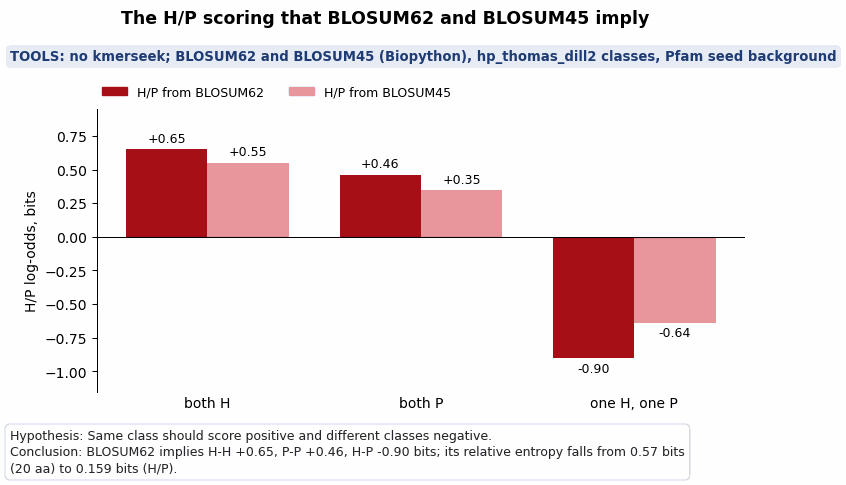

In [2]:
cls = hc.TABLES[HP][np.frombuffer(hc.PROTEIN20_ORDER.encode(), dtype=np.uint8)]
i_h, i_p = int(np.flatnonzero(cls == 0)[0]), int(np.flatnonzero(cls == 1)[0])
rows = []
for name, lam, p in [("BLOSUM62", lam62, p62), ("BLOSUM45", lam45, p45)]:
    s20 = SCHEMES[name]
    shp = SCHEMES[f"H/P from {name}"]
    rows.append(
        {
            "matrix": name,
            "lambda (bits per score unit)": round(lam, 4),
            "relative entropy, 20 aa (bits)": round(float((p * s20).sum()), 3),
            "relative entropy, H/P from it (bits)": round(float((p * shp).sum()), 3),
            "H-H": round(float(shp[i_h, i_h]), 3),
            "P-P": round(float(shp[i_p, i_p]), 3),
            "H-P": round(float(shp[i_h, i_p]), 3),
        }
    )
mat_tab = pl.DataFrame(rows)
print("Background, % of aligned residues:")
print("  ".join(f"{a} {100 * f:.1f}" for a, f in zip(hc.PROTEIN20_ORDER, background)))
print(mat_tab)

fig, ax = plt.subplots(figsize=(7.5, 3.6))
pairs = ["H-H", "P-P", "H-P"]
MATRIX_COLOR = {
    "BLOSUM62": "#a50f15",
    "BLOSUM45": "#e7969c",
}  # used only in this figure
xx = np.arange(len(pairs))
for j, r in enumerate(rows):
    vals = [r[k] for k in pairs]
    ax.bar(xx + (j - 0.5) * 0.38, vals, width=0.38, color=MATRIX_COLOR[r["matrix"]])
    for xi, v in zip(xx, vals):
        ax.text(
            xi + (j - 0.5) * 0.38,
            v + (0.03 if v > 0 else -0.03),
            f"{v:+.2f}",
            ha="center",
            va="bottom" if v > 0 else "top",
            fontsize=9,
        )
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(xx, ["both H", "both P", "one H, one P"])
ax.set_ylabel("H/P log-odds, bits")
ax.set_ylim(-1.15, 0.95)
for side in ("top", "right", "bottom"):
    ax.spines[side].set_visible(False)
ax.tick_params(axis="x", length=0)
ax.legend(
    handles=[
        Patch(color=MATRIX_COLOR[r["matrix"]], label=f"H/P from {r['matrix']}")
        for r in rows
    ],
    loc="lower left",
    bbox_to_anchor=(0, 1.02),
    ncol=2,
    frameon=False,
    fontsize=9,
    borderaxespad=0,
)
hc.finish_figure(
    fig,
    FIG / "277_hp_log_odds_implied_by_blosum62_and_blosum45.png",
    tools=f"no kmerseek; BLOSUM62 and BLOSUM45 (Biopython), {HP} classes, Pfam seed background",
    title="The H/P scoring that BLOSUM62 and BLOSUM45 imply",
    hypothesis="Same class should score positive and different classes negative.",
    conclusion=(
        f"BLOSUM62 implies H-H {rows[0]['H-H']:+.2f}, P-P {rows[0]['P-P']:+.2f}, H-P {rows[0]['H-P']:+.2f} bits; "
        f"its relative entropy falls from {rows[0]['relative entropy, 20 aa (bits)']} bits (20 aa) to "
        f"{rows[0]['relative entropy, H/P from it (bits)']} bits (H/P)."
    ),
    wrap=110,
)

## 2. SCOPe pairs by relationship: z per aligned position for each scoring

Mean bits per aligned position over the pairs in each SCOPe category, with a 95% interval from
resampling query domains. Left: all identities. Right: only the pairs under 20% identity. Grey
bars are the 20 amino acids, red bars H/P. Solid bars are substitution scorings (BLOSUM62 and
the H/P scoring it implies); hatched bars are agreement only (identity, and H/P agreement, as
in notebook 273). BLOSUM45 and its H/P scoring are in the printed table, not the figure.
Higher is better. The table also gives the aligned positions a pair at that mean needs for a
one-in-a-million chance of an unrelated pair doing as well, $20/\text{bits}$, and the mean z per
position.

SCOPe, all identities: mean per pair, 95% interval resampling query domains
shape: (24, 9)
┌──────────────────────────────┬───────────────────┬───────┬────────────┬───────────────────┬────────┬────────┬──────────────────────────────┬────────────────┐
│ category                     ┆ scheme            ┆ pairs ┆ mean score ┆ bits per position ┆ 95% lo ┆ 95% hi ┆ positions for 1 in a million ┆ z per position │
│ ---                          ┆ ---               ┆ ---   ┆ ---        ┆ ---               ┆ ---    ┆ ---    ┆ ---                          ┆ ---            │
│ enum                         ┆ enum              ┆ i64   ┆ f64        ┆ f64               ┆ f64    ┆ f64    ┆ i64                          ┆ f64            │
╞══════════════════════════════╪═══════════════════╪═══════╪════════════╪═══════════════════╪════════╪════════╪══════════════════════════════╪════════════════╡
│ same_family                  ┆ identity          ┆ 11117 ┆ 0.212      ┆ 0.2053            ┆ 0.2009 ┆ 0.2097


Decision rule test, SCOPe all identities: H/P scorings minus BLOSUM45
shape: (8, 7)
┌──────────────────────────────┬─────────────────────────────────┬───────┬─────────────────────────────────┬─────────┬─────────┬───────────┐
│ category                     ┆ comparison                      ┆ pairs ┆ mean difference, bits_per_posi… ┆ 95% lo  ┆ 95% hi  ┆ H/P ahead │
│ ---                          ┆ ---                             ┆ ---   ┆ ---                             ┆ ---     ┆ ---     ┆ ---       │
│ enum                         ┆ str                             ┆ i64   ┆ f64                             ┆ f64     ┆ f64     ┆ bool      │
╞══════════════════════════════╪═════════════════════════════════╪═══════╪═════════════════════════════════╪═════════╪═════════╪═══════════╡
│ same_family                  ┆ H/P agreement minus BLOSUM45    ┆ 11117 ┆ -0.1843                         ┆ -0.1884 ┆ -0.18   ┆ false     │
│ same_family                  ┆ H/P from BLOSUM45 minus BLOSUM… ┆ 11

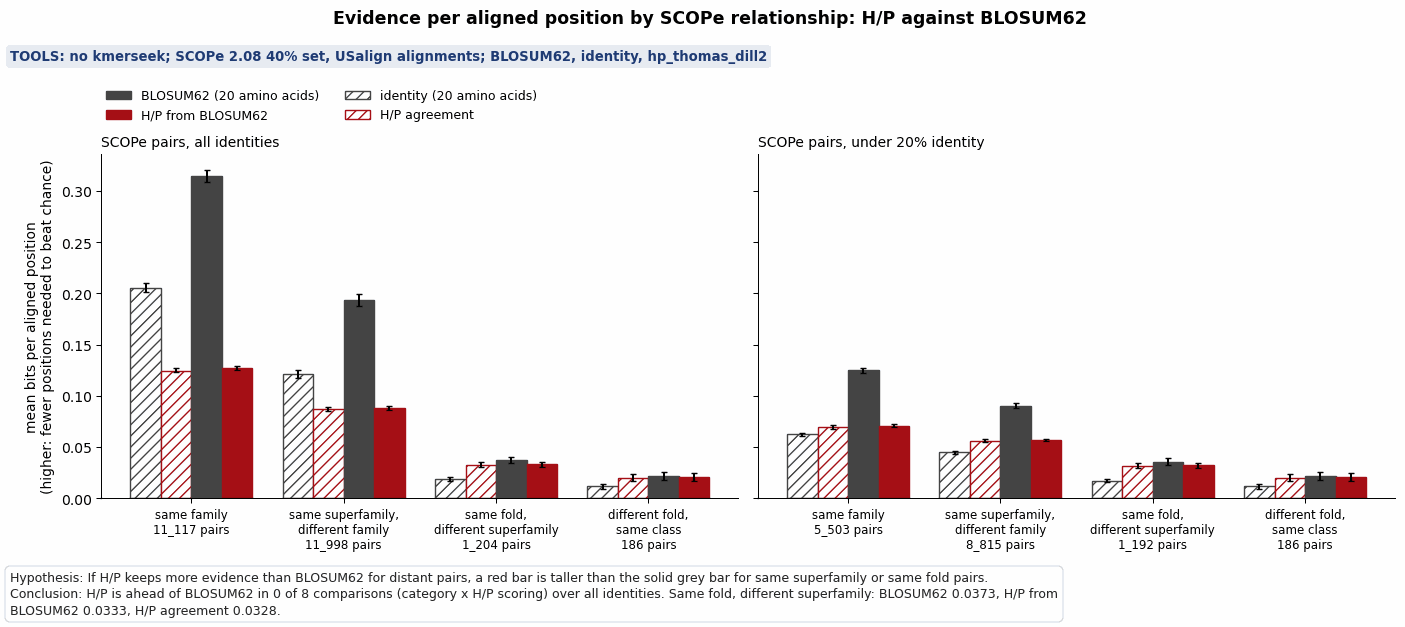

In [3]:
ENUMS = {"category": CAT_ORDER, "identity_bin": hc.IDENTITY_LABELS}


def with_order(df, by):
    return df.with_columns(
        pl.col("scheme").cast(pl.Enum(SCHEME_ORDER)),
        *[pl.col(c).cast(pl.Enum(ENUMS[c])) for c in by],
    ).sort(by + ["scheme"])


def summarise(df, by, cluster):
    rows = []
    for key, g in df.group_by(by + ["scheme"]):
        m, lo, hi = hc.cluster_bootstrap_mean_ci(
            g["bits_per_position"], g[cluster], N_BOOT, SEED
        )
        rows.append(
            dict(zip(by + ["scheme"], key))
            | {
                "pairs": g.height,
                "mean score": round(float(g["score"].mean()), 3),
                "bits per position": round(m, 4),
                "95% lo": round(lo, 4),
                "95% hi": round(hi, 4),
                "positions for 1 in a million": round(20 / m) if m > 0 else None,
                "z per position": round(float(g["z_per_position"].mean()), 3),
            }
        )
    return with_order(pl.DataFrame(rows), by)


def differences(df, by, cluster, against="BLOSUM62", metric="bits_per_position"):
    # Per pair: H/P scoring minus BLOSUM, then the mean with a cluster-resampled interval.
    wide = df.pivot(
        on="scheme",
        index=["query", "target"]
        + [c for c in by + [cluster] if c not in ("query", "target")],
        values=metric,
    )
    rows = []
    for key, g in wide.group_by(by):
        for hp_name in ["H/P agreement", f"H/P from {against}"]:
            m, lo, hi = hc.cluster_bootstrap_mean_ci(
                g[hp_name] - g[against], g[cluster], N_BOOT, SEED
            )
            rows.append(
                dict(zip(by, key))
                | {
                    "comparison": f"{hp_name} minus {against}",
                    "pairs": g.height,
                    f"mean difference, {metric}": round(m, 4),
                    "95% lo": round(lo, 4),
                    "95% hi": round(hi, 4),
                    "H/P ahead": lo > 0,
                }
            )
    return (
        pl.DataFrame(rows)
        .with_columns(*[pl.col(c).cast(pl.Enum(ENUMS[c])) for c in by])
        .sort(by + ["comparison"])
    )


scope_lo = scope.filter(pl.col("identity_bin") == "<20%")
sc_all = summarise(scope, ["category"], "query")
sc_lo = summarise(scope_lo, ["category"], "query")
print("SCOPe, all identities: mean per pair, 95% interval resampling query domains")
print(sc_all)
print("\nSCOPe, pairs under 20% identity only")
print(sc_lo)
diff_tabs = {}
for against in ["BLOSUM62", "BLOSUM45"]:
    d_all = differences(scope, ["category"], "query", against)
    d_lo = differences(scope_lo, ["category"], "query", against)
    diff_tabs[against] = d_all
    print(f"\nDecision rule test, SCOPe all identities: H/P scorings minus {against}")
    print(d_all)
    print(f"Same, pairs under 20% identity only (not part of the rule)")
    print(d_lo)
d_z = differences(scope, ["category"], "query", "BLOSUM62", "z_per_position")
print(
    "\nThe same test on z per position (not used for the decision): H/P scorings minus BLOSUM62, all identities"
)
print(d_z)

SHOWN = ["identity", "H/P agreement", "BLOSUM62", "H/P from BLOSUM62"]
COLOR = {"20 amino acids": "#444444", "H/P": "#a50f15"}  # notebook 230/273 colours
HATCH = {
    "identity": "///",
    "H/P agreement": "///",
    "BLOSUM62": None,
    "H/P from BLOSUM62": None,
}
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
x = np.arange(len(CAT_ORDER))
w = 0.2
for ax, tab, used in [
    (axes[0], sc_all, "all identities"),
    (axes[1], sc_lo, "under 20% identity"),
]:
    for j, name in enumerate(SHOWN):
        t = tab.filter(pl.col("scheme") == name).sort("category")
        m = t["bits per position"].to_numpy()
        err = np.vstack([m - t["95% lo"].to_numpy(), t["95% hi"].to_numpy() - m])
        ax.bar(
            x + (j - 1.5) * w,
            m,
            width=w,
            yerr=err,
            capsize=2,
            ecolor="black",
            color="white" if HATCH[name] else COLOR[ALPHABET_OF[name]],
            edgecolor=COLOR[ALPHABET_OF[name]],
            hatch=HATCH[name],
            lw=1.0,
        )
    npairs = (
        tab.filter(pl.col("scheme") == "BLOSUM62").sort("category")["pairs"].to_list()
    )
    ax.set_xticks(
        x,
        [f"{CAT_LABEL[c]}\n{n:_} pairs" for c, n in zip(CAT_ORDER, npairs)],
        fontsize=8.5,
    )
    ax.set_title(f"SCOPe pairs, {used}", loc="left", fontsize=10)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
axes[0].set_ylabel(
    "mean bits per aligned position\n(higher: fewer positions needed to beat chance)"
)
handles = [
    Patch(
        facecolor=COLOR["20 amino acids"],
        edgecolor=COLOR["20 amino acids"],
        label="BLOSUM62 (20 amino acids)",
    ),
    Patch(facecolor=COLOR["H/P"], edgecolor=COLOR["H/P"], label="H/P from BLOSUM62"),
    Patch(
        facecolor="white",
        edgecolor=COLOR["20 amino acids"],
        hatch="///",
        label="identity (20 amino acids)",
    ),
    Patch(
        facecolor="white", edgecolor=COLOR["H/P"], hatch="///", label="H/P agreement"
    ),
]
axes[0].legend(
    handles=handles,
    loc="lower left",
    bbox_to_anchor=(0, 1.08),
    ncol=2,
    frameon=False,
    fontsize=9,
    borderaxespad=0,
)
d62 = diff_tabs["BLOSUM62"]
n_ahead = int(d62["H/P ahead"].sum())
sfd = sc_all.filter(pl.col("category") == "same_fold_diff_superfamily")
z_b = sfd.filter(pl.col("scheme") == "BLOSUM62")["bits per position"][0]
z_h = sfd.filter(pl.col("scheme") == "H/P from BLOSUM62")["bits per position"][0]
z_a = sfd.filter(pl.col("scheme") == "H/P agreement")["bits per position"][0]
hc.finish_figure(
    fig,
    FIG / "277_bits_per_position_hp_vs_blosum62_by_scope_relationship.png",
    tools=f"no kmerseek; SCOPe 2.08 40% set, USalign alignments; BLOSUM62, identity, {HP}",
    title="Evidence per aligned position by SCOPe relationship: H/P against BLOSUM62",
    hypothesis=(
        "If H/P keeps more evidence than BLOSUM62 for distant pairs, a red bar is taller than the "
        "solid grey bar for same superfamily or same fold pairs."
    ),
    conclusion=(
        f"H/P is ahead of BLOSUM62 in {n_ahead} of {d62.height} comparisons (category x H/P scoring) over all identities. "
        f"Same fold, different superfamily: BLOSUM62 {z_b}, H/P from BLOSUM62 {z_h}, H/P agreement {z_a}."
    ),
)

## 3. Pfam seed pairs by identity

The same measure on the Pfam seed pairs, by identity bin, with a 95% interval from resampling
families. Read with the caveat above: identity is the 20 amino acid agreement, so in the
lowest bins the 20 amino acid scorings are held down by the choice of bin. In notebook 273
this is what put H/P agreement ahead of identity under 20%. The question here is whether that
also puts H/P ahead of BLOSUM62.

Pfam seed pairs by identity: mean per pair, 95% interval resampling families
shape: (30, 9)
┌──────────────┬───────────────────┬───────┬────────────┬───────────────────┬────────┬────────┬──────────────────────────────┬────────────────┐
│ identity_bin ┆ scheme            ┆ pairs ┆ mean score ┆ bits per position ┆ 95% lo ┆ 95% hi ┆ positions for 1 in a million ┆ z per position │
│ ---          ┆ ---               ┆ ---   ┆ ---        ┆ ---               ┆ ---    ┆ ---    ┆ ---                          ┆ ---            │
│ enum         ┆ enum              ┆ i64   ┆ f64        ┆ f64               ┆ f64    ┆ f64    ┆ i64                          ┆ f64            │
╞══════════════╪═══════════════════╪═══════╪════════════╪═══════════════════╪════════╪════════╪══════════════════════════════╪════════════════╡
│ <20%         ┆ identity          ┆ 16407 ┆ 0.164      ┆ 0.0908            ┆ 0.0899 ┆ 0.0916 ┆ 220                          ┆ 0.408          │
│ <20%         ┆ H/P agreement     ┆ 16407 ┆


H/P scorings minus BLOSUM62, Pfam, by identity bin
shape: (10, 7)
┌──────────────┬─────────────────────────────────┬───────┬─────────────────────────────────┬─────────┬─────────┬───────────┐
│ identity_bin ┆ comparison                      ┆ pairs ┆ mean difference, bits_per_posi… ┆ 95% lo  ┆ 95% hi  ┆ H/P ahead │
│ ---          ┆ ---                             ┆ ---   ┆ ---                             ┆ ---     ┆ ---     ┆ ---       │
│ enum         ┆ str                             ┆ i64   ┆ f64                             ┆ f64     ┆ f64     ┆ bool      │
╞══════════════╪═════════════════════════════════╪═══════╪═════════════════════════════════╪═════════╪═════════╪═══════════╡
│ <20%         ┆ H/P agreement minus BLOSUM62    ┆ 16407 ┆ -0.0923                         ┆ -0.0936 ┆ -0.091  ┆ false     │
│ <20%         ┆ H/P from BLOSUM62 minus BLOSUM… ┆ 16407 ┆ -0.0905                         ┆ -0.0918 ┆ -0.0892 ┆ false     │
│ 20-30%       ┆ H/P agreement minus BLOSUM62    ┆ 37085 ┆

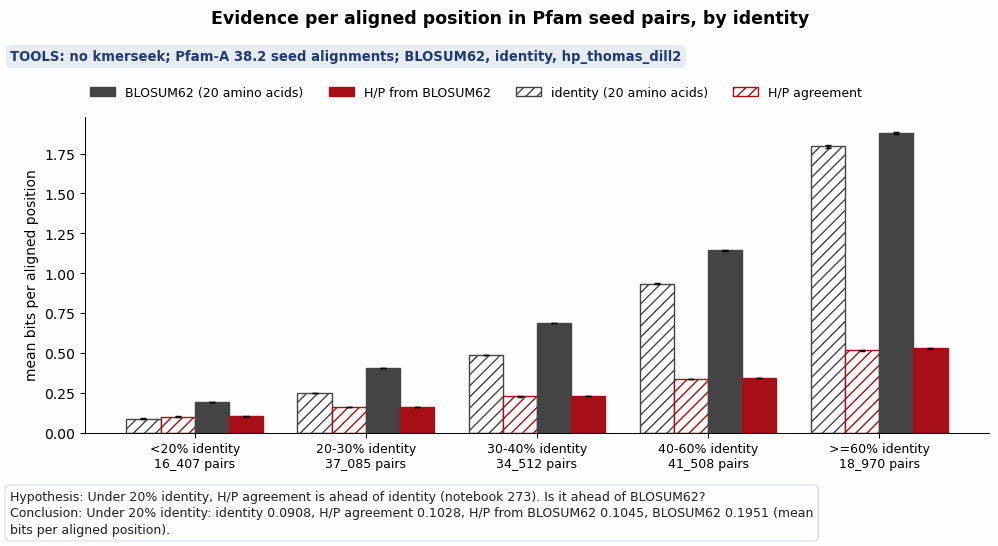

In [4]:
pf_tab = summarise(pfam, ["identity_bin"], "family")
print("Pfam seed pairs by identity: mean per pair, 95% interval resampling families")
print(pf_tab)
pf_diff = differences(pfam, ["identity_bin"], "family", "BLOSUM62")
print("\nH/P scorings minus BLOSUM62, Pfam, by identity bin")
print(pf_diff)

fig, ax = plt.subplots(figsize=(10, 4.2))
x = np.arange(len(hc.IDENTITY_LABELS))
for j, name in enumerate(SHOWN):
    t = pf_tab.filter(pl.col("scheme") == name).sort("identity_bin")
    m = t["bits per position"].to_numpy()
    err = np.vstack([m - t["95% lo"].to_numpy(), t["95% hi"].to_numpy() - m])
    ax.bar(
        x + (j - 1.5) * w,
        m,
        width=w,
        yerr=err,
        capsize=2,
        ecolor="black",
        color="white" if HATCH[name] else COLOR[ALPHABET_OF[name]],
        edgecolor=COLOR[ALPHABET_OF[name]],
        hatch=HATCH[name],
        lw=1.0,
    )
npairs = (
    pf_tab.filter(pl.col("scheme") == "BLOSUM62")
    .sort("identity_bin")["pairs"]
    .to_list()
)
ax.set_xticks(
    x,
    [f"{b} identity\n{n:_} pairs" for b, n in zip(hc.IDENTITY_LABELS, npairs)],
    fontsize=9,
)
ax.set_ylabel("mean bits per aligned position")
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.legend(
    handles=handles,
    loc="lower left",
    bbox_to_anchor=(0, 1.04),
    ncol=4,
    frameon=False,
    fontsize=9,
    borderaxespad=0,
)
lo_row = pf_tab.filter(pl.col("identity_bin") == "<20%")
zb = lo_row.filter(pl.col("scheme") == "BLOSUM62")["bits per position"][0]
zi = lo_row.filter(pl.col("scheme") == "identity")["bits per position"][0]
za = lo_row.filter(pl.col("scheme") == "H/P agreement")["bits per position"][0]
zh = lo_row.filter(pl.col("scheme") == "H/P from BLOSUM62")["bits per position"][0]
hc.finish_figure(
    fig,
    FIG / "277_bits_per_position_hp_vs_blosum62_pfam_seed_by_identity.png",
    tools=f"no kmerseek; Pfam-A 38.2 seed alignments; BLOSUM62, identity, {HP}",
    title="Evidence per aligned position in Pfam seed pairs, by identity",
    hypothesis="Under 20% identity, H/P agreement is ahead of identity (notebook 273). Is it ahead of BLOSUM62?",
    conclusion=(
        f"Under 20% identity: identity {zi}, H/P agreement {za}, H/P from BLOSUM62 {zh}, BLOSUM62 {zb} "
        "(mean bits per aligned position)."
    ),
)

## 4. Summary and conclusions

**Question.** Notebook 273 found H/P giving 1.13 times the evidence per aligned position of
the 20 amino acids in Pfam pairs under 20% identity, with the 20 amino acids scored by
identity. Does H/P still give more when the 20 amino acids are scored with BLOSUM62?

**Answer.** No. BLOSUM62 gives more evidence per aligned position than either H/P scoring in
every SCOPe relationship and every Pfam identity bin. The decision rule's test: H/P is ahead
of BLOSUM62 in 0 of 8 comparisons.

1. Pfam pairs under 20% identity, the bin where notebook 273 found the H/P lead (16,407
   pairs): identity 0.0908 bits per aligned position, H/P agreement 0.1028 (the 1.13 times),
   H/P from BLOSUM62 0.1045, BLOSUM62 0.1951. BLOSUM62 gives 1.90 times what H/P agreement
   gives. A pair at those means needs about 103 aligned positions with BLOSUM62 and 195 with
   H/P agreement before an unrelated pair has a one-in-a-million chance of scoring as well.
2. SCOPe, same superfamily but a different family, all identities (11,998 pairs): BLOSUM62
   0.1936 bits, H/P from BLOSUM62 0.0884, H/P agreement 0.0869. Same family: 0.3143 against
   0.1271 and 0.1247.
3. The closest gap is SCOPe same fold, different superfamily (1,204 pairs): BLOSUM62 0.0373,
   H/P from BLOSUM62 0.0333, H/P agreement 0.0328. H/P from BLOSUM62 minus BLOSUM62 is -0.0040
   bits (95% interval -0.0061 to -0.0020, resampling query domains). In different-fold pairs,
   which SCOPe calls unrelated, the two are level (interval -0.0043 to 0.0018).
4. Kept to SCOPe pairs under 20% identity, BLOSUM62 still leads in every homolog category
   (same superfamily: 0.0905 against 0.0569 and 0.0561); in different-fold pairs the two are
   level. BLOSUM45, built for more distant pairs, gives the same verdict: H/P is ahead of it in
   0 of 8 comparisons.
5. How H/P positions are scored barely matters. In every SCOPe category and in the Pfam bins
   under 30% identity, H/P from BLOSUM62 is at most 0.003 bits above plain H/P agreement
   (0.011 at 60% identity and above), against gaps of 0.001 to 1.36 bits to BLOSUM62. What H/P loses is the information inside each
   class. BLOSUM62's own relative entropy is 0.57 bits per position; summed into H and P it is
   0.159.
6. The z per position measure agrees on BLOSUM62 (ahead in all 8 comparisons). It differs from
   bits on identity against H/P agreement: under 20% identity it ranks identity higher (0.408
   against 0.355), the opposite of notebook 273. z assumes chance scores are spread like a bell
   curve, which is far off when chance agreement is as low as identity's (about 6.5 per 100 under 20%
   identity, notebook 273), so bits decide.

**Limits.**
* Aligned positions only, with the alignment given (Pfam seed, or USalign for SCOPe). Finding
  the alignment is a separate problem; exact k-mers see less (notebook 230).
* The residue background is the Pfam seed composition, also used for the SCOPe pairs. The
  BLOSUM62 scale factor it gives, 0.4595 bits per score unit, matches the published 0.3176 nats.
* The decision rule was written after a pilot on the same data and after switching from z to
  bits. Both measures give the same BLOSUM62 verdict, so the switch does not change it.
* SCOPe intervals resample query domains, not superfamilies; the table has no superfamily
  column for the pairs.

**Decision.** The 1.13 is not a headline. It holds only against identity scoring, which no
aligner uses. Against BLOSUM62, H/P gives about half the evidence per aligned position, with
the gap smallest for same-fold pairs from different superfamilies. The case for the H/P
alphabet cannot rest on evidence per aligned position; the divergence-time test is not worth
running for this claim. What H/P might still offer is elsewhere: tolerance of the alignment
being unknown, k-mer speed, or no structure needed, each to be tested on its own.